# Verificación de la división train / validación / test

**Por qué este notebook:** en las curvas del notebook 03 la pérdida de validación queda por debajo de la de
entrenamiento. Las causas normales son el aumento de datos y el momento en que se mide cada una. Las causas que sí serían
un problema son tres, y aquí se comprueban una por una:

| Pregunta | Sección |
|---|---|
| ¿La división se creó correctamente? | 1 |
| ¿Hay fuga de datos entre train, validación y test? | 2 |
| ¿Los CT de validación son más fáciles que los de entrenamiento? | 3 |

**De dónde salen los datos:** `splits/splits.csv`, la tabla por caso del EDA (`results/eda/case_table.csv`), la
evaluación del modelo `unet3d_cbam_trab` y `scripts/verificar_division.py`, que vuelve a crear la división, compara
los 100 CT entre sí y mide la pérdida del modelo final **sin aumento** en los 100 CT (`results/splits/`).

In [1]:
import inspect
import json
import re
import subprocess
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency, kruskal, mannwhitneyu

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))
from src import config

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 9})
SPLITS = ("train", "val", "test")
COLOR = {"train": "tab:blue", "val": "tab:orange", "test": "tab:green"}
VER = config.RESULTS_DIR / "splits"
splits = pd.read_csv(config.SPLITS_DIR / "splits.csv", dtype={"case_id": str})
casos = pd.read_csv(config.EDA_DIR / "case_table.csv", dtype={"case_id": str})
ids = {s: set(splits.case_id[splits.split == s]) for s in SPLITS}
print({s: len(v) for s, v in ids.items()})

{'train': 70, 'val': 15, 'test': 15}


## 1. ¿La división se creó correctamente?

La división es **por caso** (un caso = un CT = un paciente en PENGWIN), 70 / 15 / 15, estratificada por tipo de
fractura (`src/dataset/splits.py`, semilla `config.SEED`). Se comprueba:

1. que cada caso del dataset está en un split y solo en uno;
2. que los tamaños y la estratificación son los pedidos;
3. que el tipo de fractura guardado coincide con el que sale de las máscaras;
4. que al volver a correr el código con la misma semilla sale exactamente la misma división.

In [2]:
en_disco_img = {q.stem for d in config.IMAGE_DIRS for q in d.glob("*.mha")}
en_disco_lab = {q.stem for q in config.LABEL_DIR.glob("*.mha")}
en_cache = {q.name.removesuffix("_img.npy") for q in config.CACHE_DIR.glob("*_img.npy")}
todos = set(splits.case_id)
n = len(splits)
pruebas = {
    "casos en splits.csv": n,
    "case_id repetidos": int(splits.case_id.duplicated().sum()),
    "casos sin split o con un split desconocido": int((~splits.split.isin(SPLITS)).sum()),
    "CT en disco que no están en splits.csv": len(en_disco_img - todos),
    "casos de splits.csv sin CT o sin máscara en disco": len(todos - en_disco_img) + len(todos - en_disco_lab),
    "casos de splits.csv sin cubo en el caché": len(todos - en_cache),
    "tamaños (train / val / test)": " / ".join(str(len(ids[s])) for s in SPLITS),
    "tamaños pedidos (70 % / 15 % / 15 %)": " / ".join(str(round(n * config.SPLIT_FRACTIONS[s])) for s in SPLITS),
}
pd.Series(pruebas).to_frame("resultado")

,resultado
casos en splits.csv,100
case_id repetidos,0
casos sin split o con un split desconocido,0
CT en disco que no están en splits.csv,0
casos de splits.csv sin CT o sin máscara en disco,0
casos de splits.csv sin cubo en el caché,0
tamaños (train / val / test),70 / 15 / 15
tamaños pedidos (70 % / 15 % / 15 %),70 / 15 / 15


In [3]:
t = pd.crosstab(splits.stratum, splits.split)[list(SPLITS)]
t.loc["total"] = t.sum()
pct = (100 * t / t.loc["total"]).round(1).add_suffix(" (%)")
display(pd.concat([t, pct], axis=1))
pd.crosstab(splits.fracture_type, splits.split)[list(SPLITS)]

split,train,val,test,train (%),val (%),test (%)
stratum,,,,,,
hip_bilateral,12,3,3,17.1,20.0,20.0
hip_unilateral_or_none,27,5,5,38.6,33.3,33.3
sacrum_fractured,31,7,7,44.3,46.7,46.7
total,70,15,15,100.0,100.0,100.0


split,train,val,test
fracture_type,,,
BHF,12,3,3
PRD,1,0,0
SF,2,1,0
SHF,29,6,7
UHF,26,5,5


In [4]:
rep = pd.read_csv(VER / "reproduccion.csv", dtype={"case_id": str})
tipo_eda = casos.set_index("case_id").fracture_type.reindex(splits.case_id).values
git = subprocess.run(["git", "diff", "--quiet", "HEAD", "--", "splits/splits.csv"], cwd=PROJECT_ROOT)
pd.Series({
    "casos con el mismo split al volver a crear la división": f"{int((rep.split_csv == rep.split_recalculado).sum())} de {len(rep)}",
    "casos con el mismo tipo de fractura al volver a leer las máscaras": f"{int((rep.fracture_type_csv == rep.fracture_type_recalculado).sum())} de {len(rep)}",
    "casos con el mismo tipo de fractura que en la tabla del EDA": f"{int((splits.fracture_type.values == tipo_eda).sum())} de {len(splits)}",
    "splits.csv igual al que está en git (HEAD)": {0: "sí", 1: "no, cambió"}.get(git.returncode, "no se pudo comprobar"),
    "semilla": config.SEED,
}).to_frame("resultado")

,resultado
casos con el mismo split al volver a crear la división,100 de 100
casos con el mismo tipo de fractura al volver a leer las máscaras,100 de 100
casos con el mismo tipo de fractura que en la tabla del EDA,100 de 100
splits.csv igual al que está en git (HEAD),sí
semilla,99


**Sí, la división está bien creada.**

- **Cada caso está en un split y solo en uno:** 100 casos, ninguno repetido, ninguno sin split, y los 100 tienen CT,
  máscara y cubo en el caché.
- **Tamaños:** 70 / 15 / 15, los pedidos.
- **Estratificación:** los tres estratos quedan en proporciones parecidas en los tres splits (sacro fracturado 44-47 %,
  coxal unilateral o sin fractura 33-39 %, coxal bilateral 17-20 %). Con 15 casos no pueden quedar idénticas.
- **Tipo de fractura:** el guardado coincide en los 100 casos con el que sale hoy de las máscaras y con el del EDA.
- **Reproducible:** al volver a correr `src/dataset/splits.py` con la semilla 99 salen los mismos 100 casos en los mismos
  splits, y `splits.csv` es el mismo que está en git.
- **Un detalle:** los tipos raros (PRD, 1 caso; SF, 3 casos) no alcanzan para estar en los tres splits. Por eso se
  estratifica por estrato y no por tipo.

## 2. ¿Hay fuga de datos?

Fuga = que el modelo vea, al entrenar, información de los CT con los que después se mide. Hay tres formas de que pase:

- **2.1** el mismo caso en dos splits;
- **2.2** dos archivos distintos que son el mismo CT (o el mismo paciente escaneado dos veces) en splits distintos;
- **2.3** que algún paso del pipeline use casos de validación o test para ajustar algo.

### 2.1 Casos compartidos entre splits

In [5]:
pd.DataFrame({a: {b: len(ids[a] & ids[b]) for b in SPLITS} for a in SPLITS}).rename_axis("casos en común")

,train,val,test
casos en común,,,
train,70,0,0
val,0,15,0
test,0,0,15


### 2.2 CT repetidos o casi iguales en splits distintos

Los `.mha` no traen datos del paciente, así que no se puede comprobar por nombre. Se comprueba por contenido:

- **Copias exactas:** md5 del cubo de cada caso.
- **CT casi iguales:** cada cubo se reduce a 32³ y se calcula la correlación entre cada par de casos. Dos CT del mismo
  paciente, o el mismo CT con otro nombre, darían una correlación cercana a 1, muy por encima del resto.

La gráfica compara, para cada CT de validación y de test, el parecido con su CT **más parecido de train**, frente al
parecido de cada CT de train con su más parecido dentro de train. Si hubiera fuga, validación y test tendrían puntos
pegados a 1.

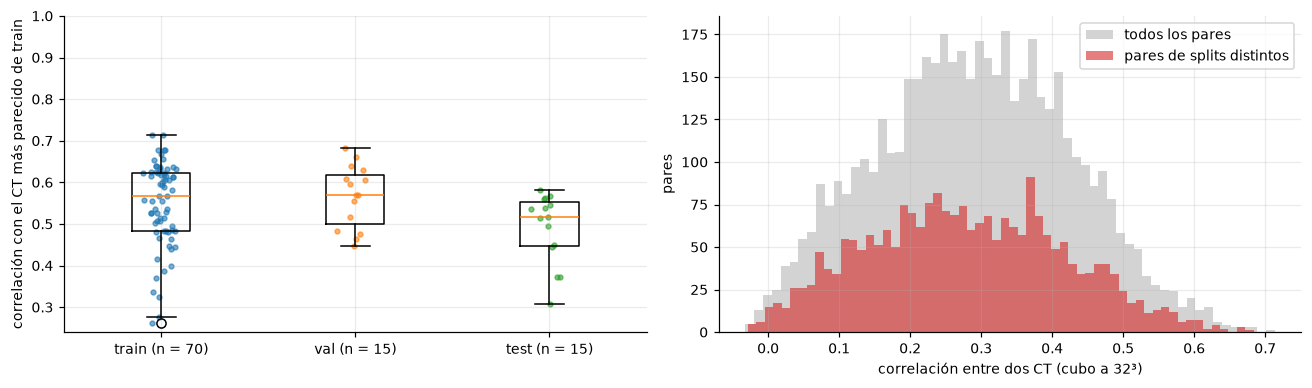

Cubos distintos (md5): 100 de 100 | correlación máxima entre splits distintos: 0.684 | máxima dentro de train: 0.713


,caso A,caso B,correlación,split A,tamaño y espaciado A,hueso A (cm³),split B,tamaño y espaciado B,hueso B (cm³)
0,015,081,0.684,train,479×281×260 · 0.82/1.00 mm,740,val,416×268×342 · 0.80/0.80 mm,860
1,081,082,0.667,val,416×268×342 · 0.80/0.80 mm,860,train,512×305×312 · 0.81/1.00 mm,803
2,002,081,0.665,train,413×276×337 · 0.82/0.80 mm,745,val,416×268×342 · 0.80/0.80 mm,860
3,038,051,0.662,train,512×512×350 · 0.78/0.80 mm,694,val,512×512×350 · 0.86/0.80 mm,858
4,050,051,0.645,train,512×345×326 · 0.68/0.80 mm,860,val,512×512×350 · 0.86/0.80 mm,858


In [6]:
z = np.load(VER / "parecido.npz")
corr = pd.DataFrame(z["corr"], index=z["case_id"], columns=z["case_id"])
sp = splits.set_index("case_id").split
tr = sp.index[sp == "train"]
vecino = {}
for s in SPLITS:
    c = corr.loc[sp.index[sp == s], tr]
    if s == "train":
        c = c.where(~np.eye(len(c), dtype=bool))                      # un CT no se compara consigo mismo
    vecino[s] = pd.DataFrame({"más parecido en train": c.idxmax(axis=1), "correlación": c.max(axis=1)})
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].boxplot([vecino[s].correlación for s in SPLITS], tick_labels=[f"{s} (n = {len(vecino[s])})" for s in SPLITS])
for i, s in enumerate(SPLITS, start=1):
    ax[0].scatter(np.random.default_rng(0).normal(i, 0.04, len(vecino[s])), vecino[s].correlación, s=10, color=COLOR[s], alpha=0.6)
ax[0].set_ylabel("correlación con el CT más parecido de train"); ax[0].set_ylim(top=1.0)
pares = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack()
entre = pares[[sp[a] != sp[b] for a, b in pares.index]]
ax[1].hist(pares, bins=60, color="lightgrey", label="todos los pares")
ax[1].hist(entre, bins=60, color="tab:red", alpha=0.6, label="pares de splits distintos")
ax[1].set_xlabel("correlación entre dos CT (cubo a 32³)"); ax[1].set_ylabel("pares"); ax[1].legend()
plt.tight_layout(); plt.show()
top = entre.sort_values(ascending=False).head(5).rename("correlación").reset_index().rename(columns={"level_0": "caso A", "level_1": "caso B"})
geo = casos.set_index("case_id")
for lado in ("A", "B"):
    top[f"split {lado}"] = top[f"caso {lado}"].map(sp)
    top[f"tamaño y espaciado {lado}"] = top[f"caso {lado}"].map(
        lambda c: f"{geo.dim_x[c]}×{geo.dim_y[c]}×{geo.dim_z[c]} · {geo.spacing_x[c]:.2f}/{geo.spacing_z[c]:.2f} mm")
    top[f"hueso {lado} (cm³)"] = top[f"caso {lado}"].map(lambda c: round(geo.bone_volume_mm3[c] / 1000))
print(f"Cubos distintos (md5): {len(set(z['md5']))} de {len(z['md5'])} | correlación máxima entre splits distintos: "
      f"{entre.max():.3f} | máxima dentro de train: {vecino['train'].correlación.max():.3f}")
top.round(3)

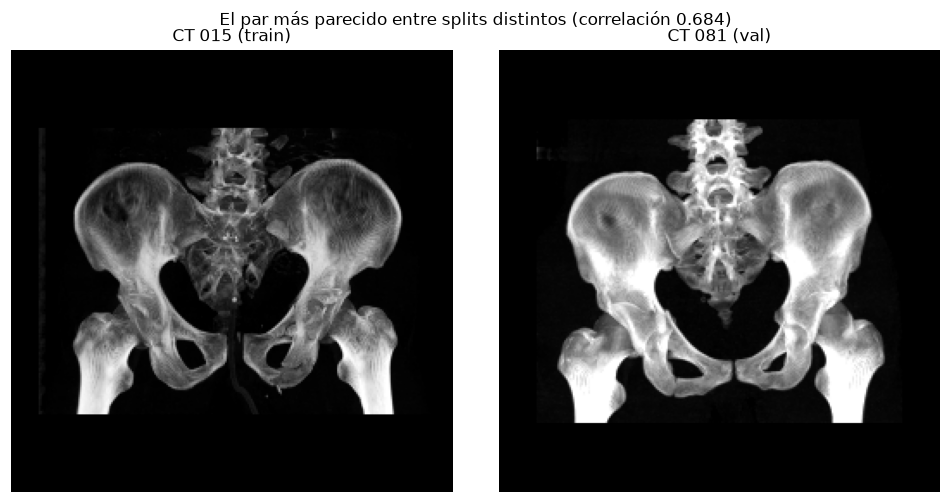

In [7]:
# Los dos CT más parecidos de splits distintos, lado a lado (proyección de máxima intensidad coronal)
a, b = top.loc[0, "caso A"], top.loc[0, "caso B"]
fig, ax = plt.subplots(1, 2, figsize=(9, 4.6))
for eje, cid in zip(ax, (a, b)):
    cubo = np.load(config.CACHE_DIR / f"{cid}_img.npy", mmap_mode="r")
    eje.imshow(np.asarray(cubo).max(1)[::-1], cmap="gray"); eje.set_title(f"CT {cid} ({sp[cid]})"); eje.axis("off"); eje.grid(False)
plt.suptitle(f"El par más parecido entre splits distintos (correlación {top.loc[0, 'correlación']:.3f})"); plt.tight_layout(); plt.show()

### 2.3 Qué casos usa cada paso del pipeline

Se lee el código fuente de cada comando y se buscan los splits que pide (`case_ids("…")` en el modelo 3D,
`split == "…"` en las anclas). Lo esperado: lo que **ajusta** algo usa solo train; validación solo **elige** (mejor
época, margen del ajuste de cajas); test solo se usa en `evaluate`.

In [8]:
from src.models import detection as D
from src.models import model3d as M
from src.dataset import preprocessing as pre


def splits_usados(fn):
    src = inspect.getsource(fn)
    usados = set(re.findall(r'case_ids\("(\w+)"\)', src)) | set(re.findall(r'split == "(\w+)"', src))
    if "M3D_EVAL_SPLITS" in src:                       # `evaluate` recorre config.M3D_EVAL_SPLITS
        usados |= set(config.M3D_EVAL_SPLITS)
    return sorted(usados, key=SPLITS.index)


pasos = [("Preprocesamiento (cubo, ventana HU)", pre.preprocess_volume, "nada: ventana HU y tamaño fijos, caso por caso"),
         ("Anclas de la detección", D.anchors, "escalas y proporciones de las cajas"),
         ("Calibración de los λ", M.calibrate, "pérdida inicial de cada cabeza"),
         ("Prueba de sobreajuste", M.overfit, "ninguna decisión del modelo final"),
         ("Entrenamiento", M.train, "pesos (train); mejor época (val)"),
         ("Evaluación", M.evaluate, "métricas; margen del ajuste de cajas (val)")]
tabla = pd.DataFrame([{"paso": p, "splits que lee": ", ".join(splits_usados(f)) or "ninguno (no mira el split)", "qué ajusta o decide": q}
                      for p, f, q in pasos]).set_index("paso")
src_train = inspect.getsource(M.train)
print("El DataLoader de entrenamiento se construye con:", re.search(r"VolumeDataset\((\w+)", src_train).group(1),
      "| `test` aparece en train():", '"test"' in src_train)
cfg = json.loads((config.DETECTION_DIR / config.M3D_RUN_CBAM / "config.json").read_text())
print("Semilla guardada en la configuración del entrenamiento:", cfg.get("seed"), "| semilla de la división:", config.SEED)
tabla

El DataLoader de entrenamiento se construye con: tr_ids | `test` aparece en train(): False
Semilla guardada en la configuración del entrenamiento: 99 | semilla de la división: 99


,splits que lee,qué ajusta o decide
paso,,
"Preprocesamiento (cubo, ventana HU)",ninguno (no mira el split),"nada: ventana HU y tamaño fijos, caso por caso"
Anclas de la detección,train,escalas y proporciones de las cajas
Calibración de los λ,train,pérdida inicial de cada cabeza
Prueba de sobreajuste,train,ninguna decisión del modelo final
Entrenamiento,"train, val",pesos (train); mejor época (val)
Evaluación,"val, test",métricas; margen del ajuste de cajas (val)


**No se encontró fuga de datos.**

- **Casos compartidos:** ninguno entre train, validación y test.
- **Copias exactas:** los 100 cubos son distintos.
- **CT casi iguales:** el par más parecido entre splits distintos tiene correlación 0,68; dentro de train el máximo es
  0,71. Validación y test no se parecen a train más de lo que los CT de train se parecen entre sí. En la figura, el par
  más parecido son dos pelvis distintas (otra forma del sacro y de las alas ilíacas, otro tamaño).
- **Pipeline:** las anclas, la calibración de los λ y los pesos se ajustan solo con train. El preprocesamiento no
  ajusta nada con los datos (ventana HU y tamaño fijos, caso por caso). `test` no aparece en el entrenamiento.

**Lo que sí usa validación (no es fuga, pero hay que saberlo):**
- la **mejor época** (`best.pth`) se elige con las métricas de validación;
- el **margen del ajuste de cajas** se elige en validación y se aplica igual en test.

Por eso los números de validación son un poco optimistas y **el número que se reporta es el de test**, que no se usó
para decidir nada.

**Lo que no se puede comprobar con los archivos:** que cada CT sea de un paciente distinto. Los `.mha` no traen datos
del paciente; PENGWIN lo documenta así (100 pacientes). La prueba de parecido es el sustituto: no hay dos CT que
parezcan el mismo.

## 3. ¿Los CT de validación son más fáciles?

Dos formas de mirarlo:

- **3.1 Por las características de los CT** (sin usar ningún modelo): fragmentos, volumen de hueso, densidad, geometría.
- **3.2 Por lo que le cuesta al modelo:** la misma pérdida de la curva de validación, medida **sin aumento de datos** en
  los 100 CT. Si validación fuera más fácil, su pérdida sería más baja que la de train aun sin aumento.

### 3.1 Características de los CT por split

Con 15 CT en validación y 15 en test, las pruebas detectan solo diferencias grandes. Se usa Kruskal-Wallis entre los tres
splits y Mann-Whitney entre train y validación. Con 9 variables, alguna p < 0,05 puede salir por azar.

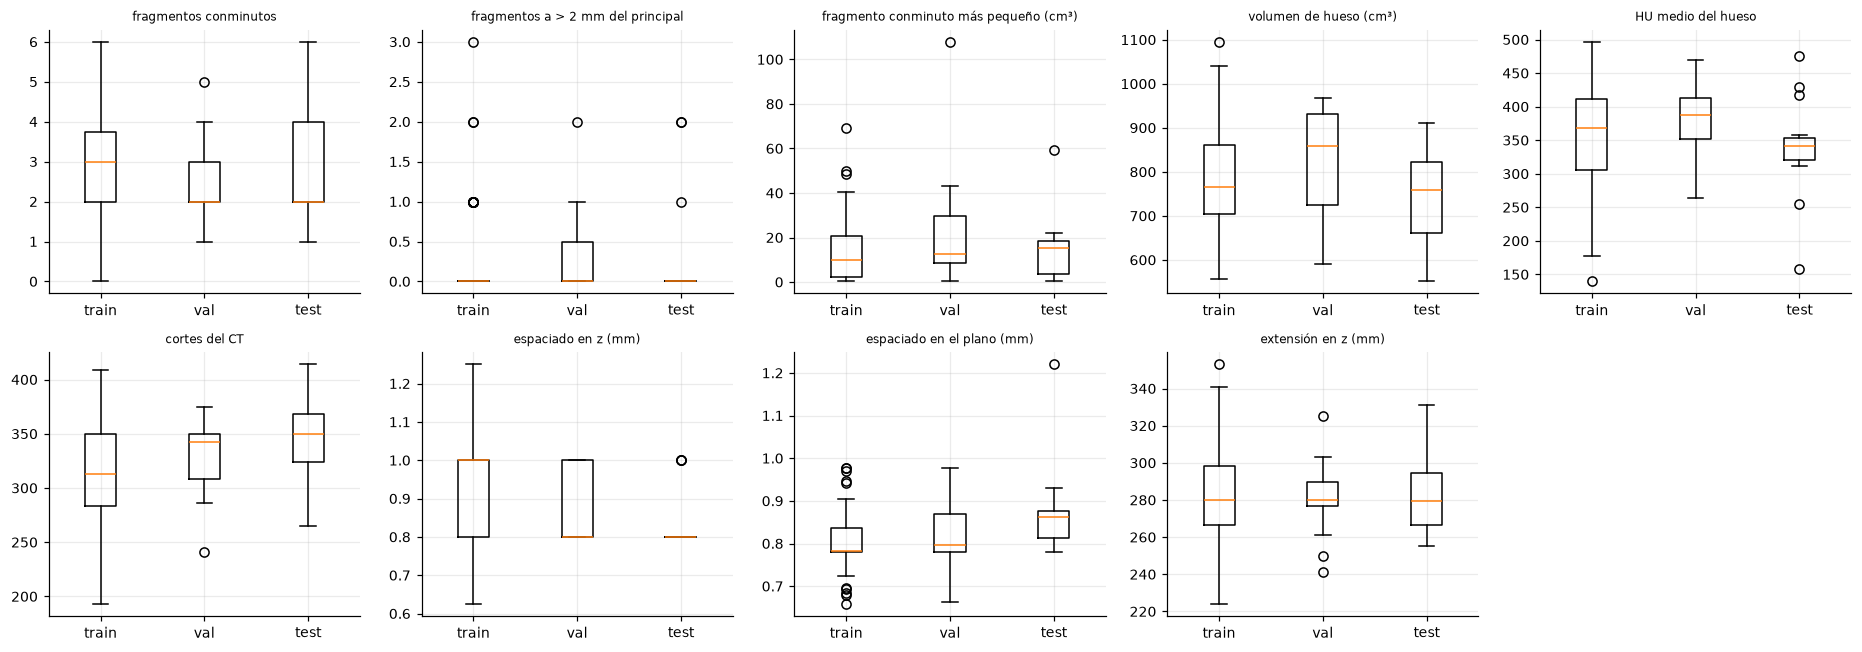

Mitad del dataset (part1 = casos 001-050, part2 = 051-100) por split:


split,train,val,test
part,,,
part1,39,3,8
part2,31,12,7


p (chi-cuadrado, mitad × split): 0.041 | p (tipo de fractura × split): 0.986


,mediana train,mediana val,mediana test,p (los tres splits),p (train frente a val)
variable,,,,,
fragmentos conminutos,3.000,2.000,2.000,0.606,0.331
fragmentos a > 2 mm del principal,0.000,0.000,0.000,0.850,0.571
fragmento conminuto más pequeño (cm³),9.905,12.518,15.295,0.397,0.172
volumen de hueso (cm³),764.601,857.967,759.033,0.164,0.228
HU medio del hueso,368.320,387.003,340.864,0.307,0.330
cortes del CT,312.500,342.000,350.000,0.089,0.232
espaciado en z (mm),1.000,0.800,0.800,0.102,0.313
espaciado en el plano (mm),0.783,0.797,0.863,0.022,0.612
extensión en z (mm),279.996,280.017,279.633,0.984,0.876


In [9]:
d = splits.merge(casos.drop(columns=["fracture_type"]), on="case_id")
gt = pd.read_csv(config.RESULTS_DIR / "distancias" / "distancias_gt_3d.csv", dtype={"case_id": str})
con = gt[~gt.principal].groupby("case_id").agg(frag_separados=("distancia_mm", lambda x: int((x > 2).sum())),
                                                frag_menor_cm3=("n_voxels", "min"))
d = d.merge(con, on="case_id", how="left").fillna({"frag_separados": 0})
d["frag_menor_cm3"] = d.frag_menor_cm3 * d.voxel_mm3 / 1000
d["hueso_cm3"] = d.bone_volume_mm3 / 1000
d["frag_conminutos"] = d.n_fragments - 3
VARS = {"frag_conminutos": "fragmentos conminutos", "frag_separados": "fragmentos a > 2 mm del principal",
        "frag_menor_cm3": "fragmento conminuto más pequeño (cm³)", "hueso_cm3": "volumen de hueso (cm³)",
        "bone_hu_mean": "HU medio del hueso", "dim_z": "cortes del CT", "spacing_z": "espaciado en z (mm)",
        "spacing_x": "espaciado en el plano (mm)", "fov_z_mm": "extensión en z (mm)"}
filas = []
for k, nombre in VARS.items():
    g = {s: d.loc[d.split == s, k].dropna() for s in SPLITS}
    filas.append({"variable": nombre, **{f"mediana {s}": g[s].median() for s in SPLITS},
                  "p (los tres splits)": kruskal(*g.values()).pvalue,
                  "p (train frente a val)": mannwhitneyu(g["train"], g["val"]).pvalue})
fig, axes = plt.subplots(2, 5, figsize=(17, 6))
for ax, (k, nombre) in zip(axes.ravel(), VARS.items()):
    ax.boxplot([d.loc[d.split == s, k].dropna() for s in SPLITS], tick_labels=SPLITS); ax.set_title(nombre, fontsize=8)
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()
parte = pd.crosstab(d.part, d.split)[list(SPLITS)]
print("Mitad del dataset (part1 = casos 001-050, part2 = 051-100) por split:"); display(parte)
print(f"p (chi-cuadrado, mitad × split): {chi2_contingency(parte).pvalue:.3f} | "
      f"p (tipo de fractura × split): {chi2_contingency(pd.crosstab(splits.fracture_type, splits.split)).pvalue:.3f}")
pd.DataFrame(filas).set_index("variable").round(3)

### 3.2 Lo que le cuesta al modelo, sin aumento de datos

`scripts/verificar_division.py` pasa los 100 CT por el modelo final (`best.pth`) en modo evaluación y sin aumento, y
calcula la misma pérdida de la curva de validación y el Dice de la cabeza semántica. En train, el modelo ya vio esos CT:
su pérdida sin aumento es lo mejor que puede dar.

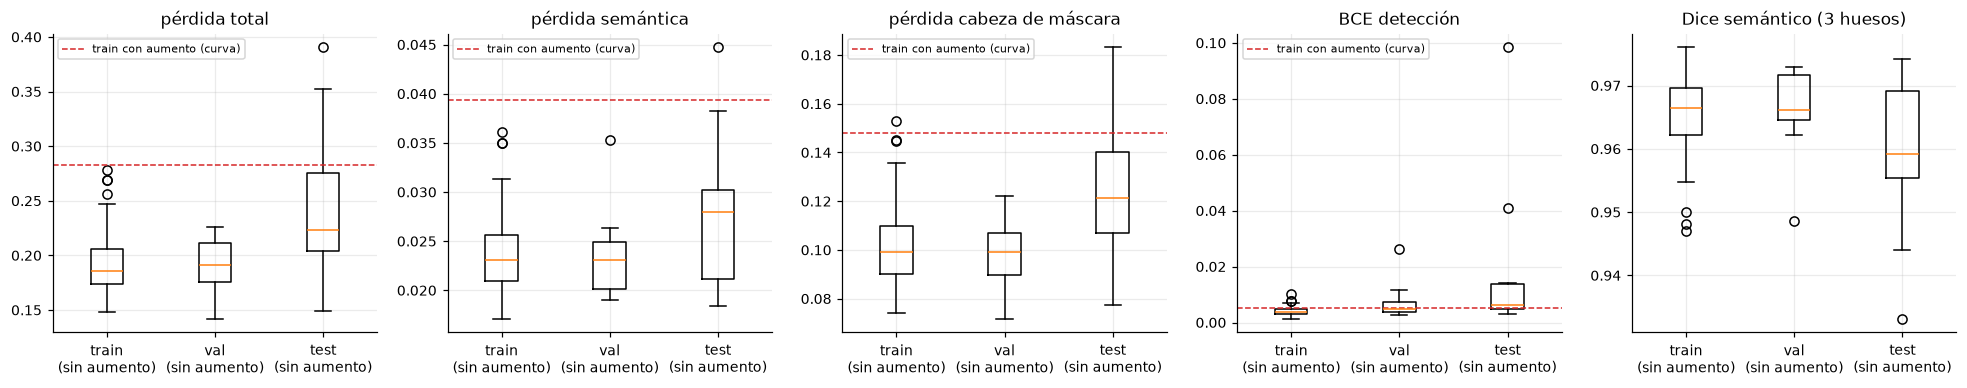

pérdida total          \
                                                  mean  median   
split                                                            
train                                           0.1915  0.1856   
val                                             0.1907  0.1911   
test                                            0.2453  0.2229   
train con aumento (curva, época elegida)        0.2827  0.2827   

                                         pérdida semántica          \
                                                      mean  median   
split                                                                
train                                               0.0238  0.0231   
val                                                 0.0234  0.0231   
test                                                0.0273  0.0280   
train con aumento (curva, época elegida)            0.0394  0.0394   

                                         pérdida cabeza de máscara          \
                                                              mean  median   
split                                                                        
train                                                       0.1013  0.0991   
val                                                         0.0983  0.0990   
test                                                        0.1227  0.1212   
train con aumento (curva, época elegida)                    0.1480  0.1480   

                                         BCE detección          \
                                                  mean  median   
split                                                            
train                                           0.0040  0.0038   
val                                             0.0067  0.0047   
test                                            0.0156  0.0061   
train con aumento (curva, época elegida)        0.0050  0.0050   

                                         Dice semántico (3 huesos)          
                                                              mean  median  
split                                                                       
train                                                       0.9659  0.9665  
val                                                         0.9665  0.9661  
test                                                        0.9603  0.9591  
train con aumento (curva, época elegida)                       NaN     NaN

,p (train sin aumento frente a val),p (val frente a test)
métrica,,
pérdida total,0.682,0.014
pérdida semántica,0.632,0.184
pérdida cabeza de máscara,0.831,0.008
BCE detección,0.052,0.089
Dice semántico (3 huesos),0.682,0.184


In [10]:
pl = pd.read_csv(VER / "perdida_sin_aumento.csv", dtype={"case_id": str})
hist = pd.read_csv(config.DETECTION_DIR / config.M3D_RUN_CBAM / "history.csv")
met = json.loads((config.DETECTION_DIR / config.M3D_RUN_CBAM / "eval" / "metrics.json").read_text())
ep = hist[hist.epoch == met["epoch"] - 1].iloc[0]
COLS = {"loss": "pérdida total", "seg": "pérdida semántica", "mask": "pérdida cabeza de máscara", "obj": "BCE detección",
        "dice_sem": "Dice semántico (3 huesos)"}
fig, axes = plt.subplots(1, 5, figsize=(18, 3.6))
for ax, (k, nombre) in zip(axes, COLS.items()):
    ax.boxplot([pl.loc[pl.split == s, k] for s in SPLITS], tick_labels=[f"{s}\n(sin aumento)" for s in SPLITS])
    if f"train_{k}" in ep.index and k != "dice_sem":
        ax.axhline(ep[f"train_{k}"], color="tab:red", ls="--", lw=1, label="train con aumento (curva)")
        ax.legend(fontsize=7)
    ax.set_title(nombre)
plt.tight_layout(); plt.show()
res = pl.groupby("split")[list(COLS)].agg(["mean", "median"]).reindex(SPLITS)
res.loc["train con aumento (curva, época elegida)"] = [v for k in COLS for v in ((ep.get(f"train_{k}", np.nan),) * 2 if k != "dice_sem" else (np.nan, np.nan))]
display(res.rename(columns=COLS).round(4))
g = {s: pl[pl.split == s] for s in SPLITS}
pd.DataFrame([{"métrica": nombre,
               "p (train sin aumento frente a val)": mannwhitneyu(g["train"][k], g["val"][k]).pvalue,
               "p (val frente a test)": mannwhitneyu(g["val"][k], g["test"][k]).pvalue} for k, nombre in COLS.items()]).set_index("métrica").round(3)

**La mitad del dataset.** En 3.1, validación tiene más casos de la segunda mitad (051-100) que train. Para saber si eso
importa, se mira si al modelo le cuesta distinto una mitad que la otra, dentro de train (70 CT, sin aumento).

In [11]:
pp = pl.merge(casos[["case_id", "part"]], on="case_id")
t = pp[pp.split == "train"]
a, b = t[t.part == "part1"], t[t.part == "part2"]
pd.DataFrame([{"métrica": nombre, "part1 (001-050)": a[k].mean(), "part2 (051-100)": b[k].mean(),
               "p (Mann-Whitney)": mannwhitneyu(a[k], b[k]).pvalue} for k, nombre in COLS.items()]).set_index("métrica").round(4)

,part1 (001-050),part2 (051-100),p (Mann-Whitney)
métrica,,,
pérdida total,0.1923,0.1905,0.8039
pérdida semántica,0.0247,0.0228,0.0686
pérdida cabeza de máscara,0.1012,0.1015,0.7675
BCE detección,0.0039,0.0041,0.7675
Dice semántico (3 huesos),0.9647,0.9674,0.0705


### 3.3 Validación frente a test en la evaluación completa

Si el modelo se hubiera ajustado de más a validación (la mejor época se eligió con ella), validación saldría claramente
mejor que test. Métricas por CT de `evaluate`.

In [12]:
ev = pd.concat([pd.read_csv(config.DETECTION_DIR / config.M3D_RUN_CBAM / "eval" / f"cases_{s}.csv", dtype={"case_id": str})
                for s in ("val", "test")])
M_EV = {"huesos_promedio_dice": "Dice semántico macro", "huesos_sacro_dice": "Dice sacro", "mascara_promedio_dice": "Dice cabeza de máscara",
        "huesos_promedio_hd95": "HD95 macro (mm)"}
filas = [{"métrica": nombre, "validación": ev.loc[ev.split == "val", k].mean(), "test": ev.loc[ev.split == "test", k].mean(),
          "p (Mann-Whitney)": mannwhitneyu(ev.loc[ev.split == "val", k], ev.loc[ev.split == "test", k]).pvalue} for k, nombre in M_EV.items()]
det_ = {s: met["splits"][s]["detection"]["raw"]["all"] for s in ("val", "test")}
filas += [{"métrica": f"Detección {k} (todo el split)", "validación": det_["val"][k], "test": det_["test"][k]} for k in ("mAP50", "mAP50_95", "mIoU")]
pd.DataFrame(filas).set_index("métrica").round(3)

,validación,test,p (Mann-Whitney)
métrica,,,
Dice semántico macro,0.955,0.952,0.407
Dice sacro,0.935,0.937,0.803
Dice cabeza de máscara,0.953,0.950,0.619
HD95 macro (mm),2.562,2.101,0.900
Detección mAP50 (todo el split),0.929,0.938,NaN
Detección mAP50_95 (todo el split),0.707,0.686,NaN
Detección mIoU (todo el split),0.875,0.861,NaN


**Validación no es más fácil que train. Sí hay un indicio de que es algo más fácil que test.**

**Por las características de los CT (3.1):**
- Ninguna variable separa train de validación (p entre 0,17 y 0,88): fragmentos, fragmentos separados, tamaño del
  fragmento más pequeño, volumen y densidad del hueso, geometría.
- La única p < 0,05 entre los tres splits es el espaciado en el plano (0,022), y es por test (0,86 mm frente a 0,78-0,80).
  Con 9 variables, una así puede salir por azar.
- Validación tiene más casos de la segunda mitad del dataset (12 de 15; p = 0,041). Dentro de train, al modelo le cuestan
  igual las dos mitades (pérdida 0,192 y 0,191), así que no explica una ventaja.
- **Límite:** con 15 CT por split estas pruebas solo detectan diferencias grandes.

**Por lo que le cuesta al modelo (3.2):**
- **Train sin aumento y validación dan la misma pérdida:** 0,192 y 0,191 (p = 0,68). También la semántica (0,024 y
  0,023) y la cabeza de máscara (0,101 y 0,098).
- **Esto explica la curva del notebook 03:** la pérdida de train con aumento es 0,283. Al quitar el aumento baja a
  0,192, que es la de validación. La brecha entre las dos curvas (0,09) es el aumento de datos, no una validación fácil.
- **Detección:** es la única cabeza con brecha real (BCE 0,0040 en train y 0,0067 en validación; p = 0,05). Es el
  sobreajuste leve que ya se veía en la curva.

**Validación frente a test (3.2 y 3.3):**
- La pérdida de test es más alta que la de validación (0,245 frente a 0,191; p = 0,014), sobre todo en la cabeza de
  máscara (p = 0,008).
- En las métricas la diferencia es pequeña y no significativa: Dice semántico 0,955 y 0,952 (p = 0,41); mAP@[0,50:0,95]
  0,707 y 0,686.
- **Lectura:** es un indicio, no una prueba (son 10 comparaciones y ninguna resistiría una corrección estricta). Hay
  dos explicaciones posibles y no se pueden separar con estos datos: la mejor época se eligió con validación, y a test le
  tocaron CT con píxel más grueso en el plano.
- **Consecuencia práctica:** ninguna para el entrenamiento. Confirma que hay que reportar test, que es lo que ya se
  hace.

## 4. Conclusión

| Pregunta | Respuesta | Evidencia |
|---|---|---|
| ¿La división se creó correctamente? | **Sí** | 100 casos, 70 / 15 / 15, estratificada, sin repetidos; se reproduce igual con la semilla 99 |
| ¿Hay fuga de datos? | **No se encontró** | 0 casos compartidos, 0 cubos repetidos, ningún par de CT casi igual; solo train ajusta pesos, anclas y λ |
| ¿Validación es más fácil que train? | **No** | mismas características; misma pérdida que train sin aumento (0,191 y 0,192) |
| ¿Validación es más fácil que test? | **Un poco, quizá** | pérdida 0,191 frente a 0,245 (p = 0,014); Dice casi igual (0,955 y 0,952) |

- **La pérdida de validación queda por debajo de la de entrenamiento por el aumento de datos.** Sin aumento, las dos
  son iguales.
- **El número que vale es el de test**, porque validación se usó para elegir la mejor época y el margen de las cajas.
- **Límites de esta verificación:** 15 CT por split dan poca potencia a las pruebas, y no hay forma de comprobar con los
  archivos que cada CT sea de un paciente distinto (se confía en la documentación de PENGWIN y en que no hay CT
  parecidos).